# 21 · Annual embedding differences and coastal evidence

**Time:** 45 minutes · **Audience:** undergraduate / introductory graduate GIS and Earth science.

**By the end:** compare aligned annual vectors; check observation support; connect candidate changes to a cautious climate study.

[Run in JupyterLite](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=21_tessera_change.ipynb) · [Earth lab](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/) · [Sources and licenses](https://jltobias.github.io/JupyterLite-zarr-sql-views/book/credits.html)

Run cells from top to bottom with **Shift+Enter**. The first kernel start downloads Python WebAssembly packages.
The bundled exercises need no data-service account. Save a copy with **File → Save and Export Notebook As** before clearing browser storage.

![Four-stage workflow: STAC discovery, Zarr reading, SQL selection, linked views](assets/pipeline.svg)

In [1]:
from course import *
import numpy as np
import matplotlib.pyplot as plt
print('Ready: Python + NumPy + local teaching data')

Ready: Python + NumPy + local teaching data


## 1. Compare the same native pixel, using the same representation

For each sampled location, calculate `1 - cosine(x_2018, x_2025)`. The result lies between 0 and 2.
It measures an annual **representation difference**. It does not identify when a change occurred or its cause.
The notebook checks coordinate alignment and uses the same model version, variant and source snapshot for all years.

Potential explanations include surface change, observation availability, preprocessing, phenology and model behavior.
Three annual samples cannot establish a climate trend or attribute change to sea-level rise.

Paired valid native pixels: 4063 of 4096


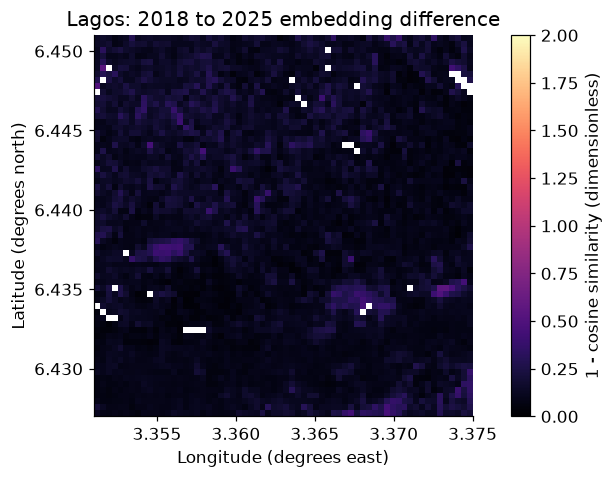

In [2]:
from tessera import load_tessera, unit_vectors, scalar_map
d=load_tessera('lagos'); U=unit_vectors(d['embedding'])
paired=d['valid'][0]&d['valid'][-1]
delta=np.where(paired,np.clip(1-np.sum(U[0]*U[-1],axis=-1),0,2),np.nan)
print('Paired valid native pixels:',paired.sum(),'of',paired.size)
fig,ax=plt.subplots();im=scalar_map(ax,d,delta,'Lagos: 2018 to 2025 embedding difference',
                                  cmap='magma',vmin=0,vmax=2)
fig.colorbar(im,ax=ax,label='1 - cosine similarity (dimensionless)');plt.show()

## 2. Put observation support beside the apparent change

Compare radar and optical counts before interpreting high scores. The dClimate run permits an embedding without radar
observations, provided its optical requirements are met. Counts can reveal a reason to investigate; they cannot isolate a cause.
We retain valid pixels in both years and never silently treat a missing vector as “no change.”

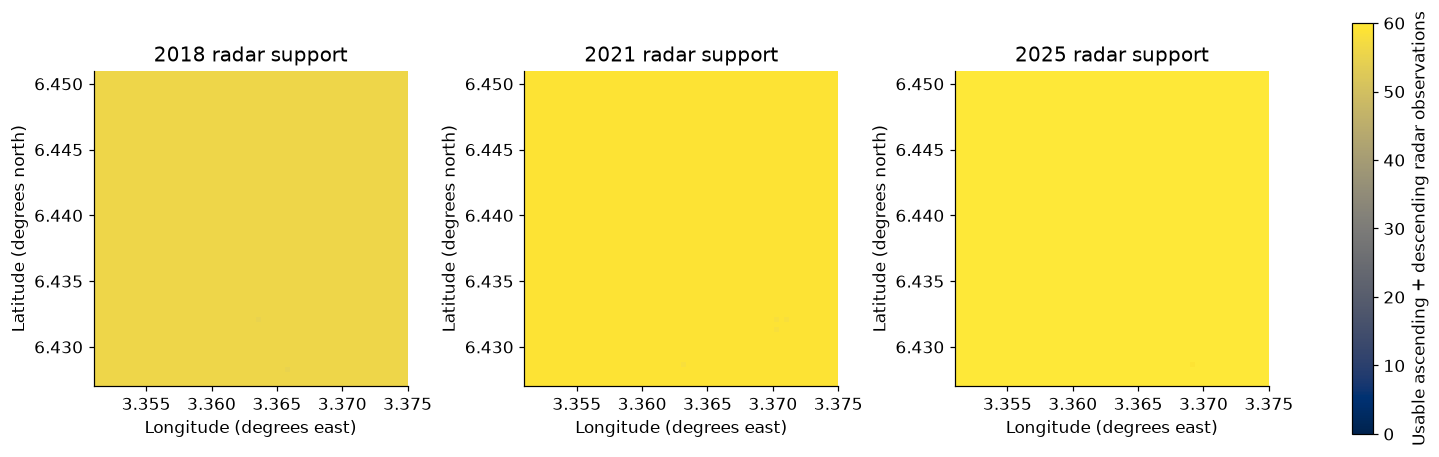

Both years: optical >= 15 and radar > 0; n = 4063 median difference = 0.1061
Both years: optical >= 30 and radar > 0; n = 111 median difference = 0.0984
Both years: optical >= 60 and radar > 0; n = 0 median difference = no supported pixels


In [3]:
radar=d['s1_asc_obs_count'].astype(np.int32)+d['s1_desc_obs_count'].astype(np.int32)
fig,axes=plt.subplots(1,3,figsize=(13,4),layout='constrained')
vmax=max(1,int(radar.max()))
for i,ax in enumerate(axes):
    im=scalar_map(ax,d,radar[i],f'{d["years"][i]} radar support',cmap='cividis',vmin=0,vmax=vmax)
fig.colorbar(im,ax=axes,label='Usable ascending + descending radar observations');plt.show()
optical_min=np.minimum(d['s2_obs_count'][0],d['s2_obs_count'][-1])
for minimum in [15,30,60]:
    selected=paired&(optical_min>=minimum)&(radar[0]>0)&(radar[-1]>0)
    print('Both years: optical >=',minimum,'and radar > 0; n =',selected.sum(),
          'median difference =',round(float(np.median(delta[selected])),4) if selected.any() else 'no supported pixels')

## 3. Watch individual locations without inventing observations between years

Here the three annual vectors at each location are compared with that location's 2018 vector. Symbols show the sampled years;
there are no interpolated observations. Compare with the fixed-reference maps from lesson 18: those answer a different question.

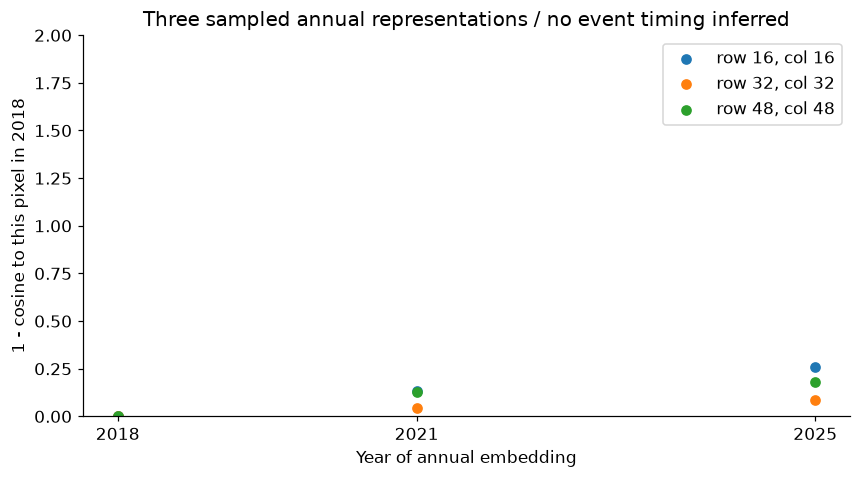

In [4]:
fig,ax=plt.subplots()
for row,col in [(16,16),(32,32),(48,48)]:
    series=np.clip(1-np.sum(U[:,row,col]*U[0,row,col],axis=-1),0,2)
    ax.scatter(d['years'],series,label=f'row {row}, col {col}')
ax.set(xticks=d['years'],xlabel='Year of annual embedding',ylabel='1 - cosine to this pixel in 2018',
       title='Three sampled annual representations / no event timing inferred',ylim=(0,2))
ax.legend();plt.show()

## 4. Build a coastal research question with independent evidence

| Candidate question | Embeddings can help with | Evidence still needed |
|---|---|---|
| Is coastal vegetation changing? | Candidate locations and sampling strata | Dated imagery, independent labels, field ecology |
| Is new construction exposed to flooding? | Candidate surface-pattern changes | Validated building footprints, terrain and datum, tides, drainage, defenses |
| Is water becoming unsafe? | Identifying places for follow-up imagery | Calibrated optical retrievals and water samples; embeddings do not measure pathogens |
| Who bears the burden? | Environmental context | Community knowledge and appropriate social data; no inferred vulnerability from appearance |

The [AR6 port-city studio](https://jltobias.github.io/JupyterLite-zarr-sql-views/book/sea-level.html) supplies conditional regional
sea-level projections. Its one-degree grid support differs enormously from these sampled 10 m pixels. Do not subtract an
embedding score from an AR6 projection or use either as an inundation map. The DE Africa lesson illustrates a separate,
observed water product at Lake Ngami; it is not co-located validation for these port windows.

Use the [C3S Atlas](https://atlas.climate.copernicus.eu/) for regional climate context and a STAC catalog for dated imagery.
Record spatial support, time, provenance, license and the proposed causal link for each layer.

In [5]:
evidence={
 'question':'Which sampled coastal locations merit independent surface-change investigation?',
 'city':d['city']['title'],'years':[int(d['years'][0]),int(d['years'][-1])],
 'metric':'1 - cosine, same native pixel, full 128-dimensional annual v1.1-dclimate vectors',
 'paired_pixels':int(paired.sum()),'median_difference':float(np.nanmedian(delta)),
 'source_snapshot':d['provenance']['snapshot_id'],
 'next_step':'Inspect dated independent imagery and observation counts before labeling any change',
 'not_established':['Climate attribution','Flood extent','Event dates','Water safety','Social vulnerability']}
print(json.dumps(evidence,indent=2))

{
  "question": "Which sampled coastal locations merit independent surface-change investigation?",
  "city": "Lagos / Apapa vicinity",
  "years": [
    2018,
    2025
  ],
  "metric": "1 - cosine, same native pixel, full 128-dimensional annual v1.1-dclimate vectors",
  "paired_pixels": 4063,
  "median_difference": 0.10610126121587138,
  "source_snapshot": "B6AFRJGX5XQC0A716PA0",
  "next_step": "Inspect dated independent imagery and observation counts before labeling any change",
  "not_established": [
    "Climate attribution",
    "Flood extent",
    "Event dates",
    "Water safety",
    "Social vulnerability"
  ]
}


## Try it yourself

Repeat for Abidjan and for 2018–2021 versus 2021–2025. Keep map limits fixed. Identify what additional data would distinguish physical surface change from changing observation support.

## Check your reasoning

A large vector difference is a candidate for investigation. It becomes a defensible environmental claim only with independent validation and an explanation consistent with temporal and spatial support.

## Evidence journal

Write four sentences: **what I observed; how I calculated it; what this cannot establish; what evidence I need next**.
For any figure you reuse, retain its units, date or scenario, data origin, transformations, and attribution.

## Sources and credit

- [TESSERA project](https://geotessera.org/) and [model repository](https://github.com/ucam-eo/tessera), University of Cambridge and collaborators.
- [Feng et al., TESSERA: Temporal Embeddings of Surface Spectra for Earth Representation and Analysis](https://doi.org/10.48550/arXiv.2506.20380), 2025, revised 2026.
- [GeoTessera Python client](https://github.com/ucam-eo/geotessera), MIT; pinned preparation commit in the provenance.
- [dClimate global-store documentation](https://github.com/dClimate/tessera-embeddings/blob/main/docs/global-store.md): annual v1.1-dclimate embeddings and observation counts.
- [Bundled source snapshot, coordinates, transformations and checksums](https://jltobias.github.io/JupyterLite-zarr-sql-views/data/tessera-provenance.json). Embedding data: CC0-1.0; [upstream terms and advisory guidelines](https://github.com/ucam-eo/tessera/blob/master/aup.md).

Teaching adaptation of [dzole0311/zarr-sql-views](https://github.com/dzole0311/zarr-sql-views), ISC.
Original teaching code and prose: JupyterLite-zarr-sql-views contributors, ISC. Data keep their separate licenses.

In [6]:
print('LESSON COMPLETE: 21_tessera_change')

LESSON COMPLETE: 21_tessera_change
